# Final Notebook: Project Group - # 44
By: Gio, Stephanie, Sidhi

Table Of Contents

1. Research Question
2. EDA Figures
3. Pipeline & Model Training
4. Model Error & Uncertainty Analysis

Links to Original Datasets: [MTG](https://mtg.github.io/mtg-jamendo-dataset/#structure
) and [GTZAN](https://www.kaggle.com/datasets/andradaolteanu/gtzan-dataset-music-genre-classification
)

The sampling and merging procedure may be replicated by running `Merging datasets.ipynb` in the `utils` subfolder.

- **Link to merged dataset in MelSpec form:** https://drive.google.com/file/d/17V6lYRQw80f7Jy2A8YlOGpIrpunKT5Q4/view?usp=sharing
- **Link to pre-trained model weights (by us):** https://drive.google.com/file/d/1BpbW3zK5387j5iIg_4EhYbvP4AZsB3Mc/view?usp=sharing

Full dependencies on which this notebook depends may be found in the zipped `requirements.txt` file.

In [1]:
#Imports
import os
import random
import numpy as np
import pandas as pd
import seaborn as sns

import matplotlib.pyplot as plt
from PIL import Image

from collections import defaultdict

# Visualization
import matplotlib.pyplot as plt
from PIL import Image

# Scikit-learn
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import permutation_test_score
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix, f1_score, accuracy_score


# PyTorch
import torch
import torch.nn as nn
import torch.optim as optim
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split, Dataset
from torchvision import datasets, models, transforms
from torchvision.models import ResNet50_Weights

import torchvision
from torchvision.transforms import functional as tvF

#Transformers
from transformers import ViTModel


# UMAP
import umap
from tqdm import tqdm
import random, json, copy

import numpy as np
import matplotlib.pyplot as plt

from utils.datasets import MultiVerticalChunkDataset, RandomVerticalChunkDataset
from utils.models import CustomResNet, UncertAwareResNet
from utils.transforms import resnet_transform_val

/home/giod/miniforge3/envs/cs209b_project/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
#Mount google drive

#from google.colab import drive
#drive.mount('/content/drive')

In [3]:
SEED = 1090
def set_seed(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    # Deterministic runs are slower; enable if you need exact reproducibility
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch:", torch.__version__)
print("torchvision:", torchvision.__version__)
print("device:", DEVICE)

torch: 2.10.0+cu128
torchvision: 0.25.0+cu128
device: cuda


# Research question

Our approach to quantifying genre ambiguity in mel spectrograms derives from the modified outputs and loss functions of neural networks for image classification proposed in [Kendall and Gal, "What Uncertainties Do We Need in Bayesian Deep Learning for Computer Vision?" (2017)](https://arxiv.org/abs/1703.04977). Specifically they propose computer vision models that output two parameters, the raw logits $\mathbf{f}_i$ and a log-variance score $\sigma_i$. Importantly, $\sigma_i$ is intended to capture aleatoric uncertainty or **uncertainty inherent due to the structure or noise of the data**, not just epistemic uncertainty that could be removed with a larger training set of the same type of data.

By shifting the logits by Gaussian noise scaled by $\sigma_i$, Kendall and Gal found both that model accuracy improved and the uncertainty metric itself became trainable. They consequently propose a new loss function based on a modification of categorical cross-entropy:

$$\hat{x}_{i,t} = f_i^{W} + \sigma_i^{W} \epsilon_t, \quad \epsilon_t \sim \mathcal{N}(0, I)$$

$$\mathcal{L}_x
= \sum_i \log \frac{1}{T} \sum_t
\exp\!\left(
\hat{x}_{i,t,c}
- \log \sum_{c'} \exp(\hat{x}_{i,t,c'})
\right)$$

Here the logits are trained conventionally, while $\sigma_i$ is trained such that it improves performance on uncertain samples but does not become so large or uniform that it interrupts certain samples. **We have received confirmation that this will meet the requirements for the 209-specific component.**

In light of Kendall and Gal's work, our core research question is:



> **When we classify music samples by genre, will multi-genre samples have significantly higher uncertainty, as represented by the log-variance outputted by the model?**



# EDA

## Distribution of genres and multigenre samples

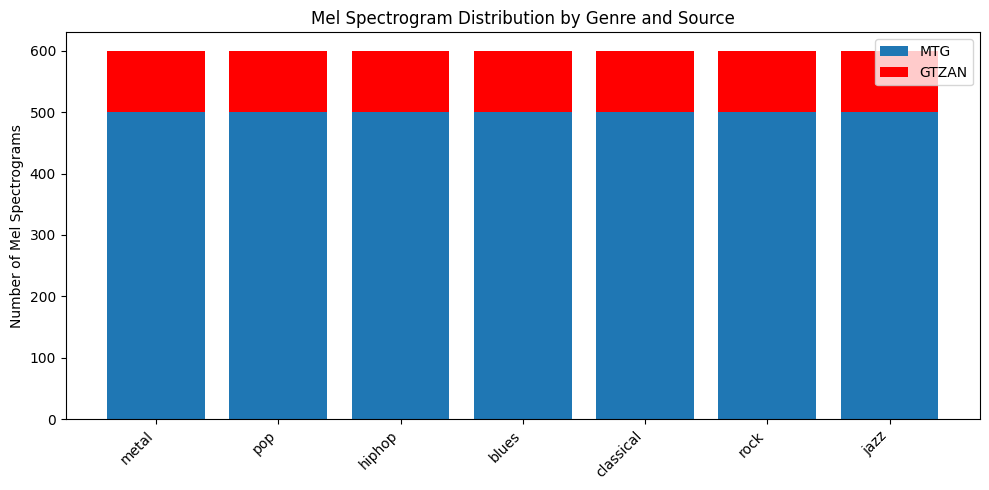

In [4]:
folder = 'Data/dataset_merged'


data = []

for genre in os.listdir(folder):
    genre_path = os.path.join(folder, genre)

    if os.path.isdir(genre_path):
        mtg_count = 0
        gtz_count = 0

        for f in os.listdir(genre_path):
            if f.lower().endswith('.png'):
                fname = f.lower()

                if 'mtg' in fname:
                    mtg_count += 1
                elif 'gtz' in fname:
                    gtz_count += 1

        total = mtg_count + gtz_count

        data.append({
            'genre': genre,
            'MTG': mtg_count,
            'GTZAN': gtz_count,
            'total': total
        })

df = pd.DataFrame(data)
df = df.sort_values(by='total', ascending=False)


plt.figure(figsize=(10, 5))

plt.bar(df['genre'], df['MTG'], label='MTG')
plt.bar(df['genre'], df['GTZAN'], bottom=df['MTG'], label='GTZAN', color='red')

plt.xticks(rotation=45, ha='right')
plt.ylabel("Number of Mel Spectrograms")
plt.title("Mel Spectrogram Distribution by Genre and Source")

plt.legend()
plt.tight_layout()
plt.show()

We assess the distribution of multi-genre vs. single-genre samples in the merged dataset.

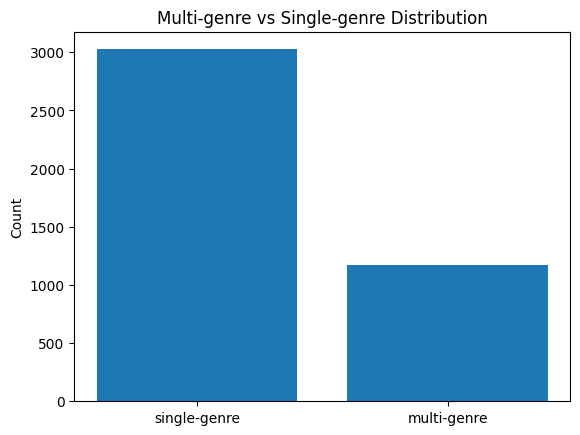

In [5]:

csv_file = "Data/dataset_merged/MTG Info for Merging.csv"

primary_df = pd.read_csv(csv_file)
primary_df["MTG_ID"] = primary_df["TRACK_ID"].str.replace("track_", "mtg_", regex=False)
mtg_lookup = dict(zip(primary_df["MTG_ID"], primary_df["MULTIGENRE"]))

seen_mtg = set()
seen_gtz = set()

for genre in os.listdir(folder):
    genre_path = os.path.join(folder, genre)

    if not os.path.isdir(genre_path):
        continue

    for f in os.listdir(genre_path):
        if not f.lower().endswith('.png'):
            continue

        name = f.replace('.png', '')

        if name.startswith("mtg_"):
            seen_mtg.add(name)
        elif name.startswith("gtz"):
            seen_gtz.add(name)

mtg_multi = sum(1 for t in seen_mtg if mtg_lookup.get(t, 0) == 1)
mtg_single = len(seen_mtg) - mtg_multi

gtzan_single = len(seen_gtz)

multi_single_counts = pd.Series({
    "single-genre": mtg_single + gtzan_single,
    "multi-genre": mtg_multi
})


plt.bar(multi_single_counts.index, multi_single_counts.values)
plt.ylabel("Count")
plt.title("Multi-genre vs Single-genre Distribution")
plt.show()

## Visualizing individual samples and sample dimensionality

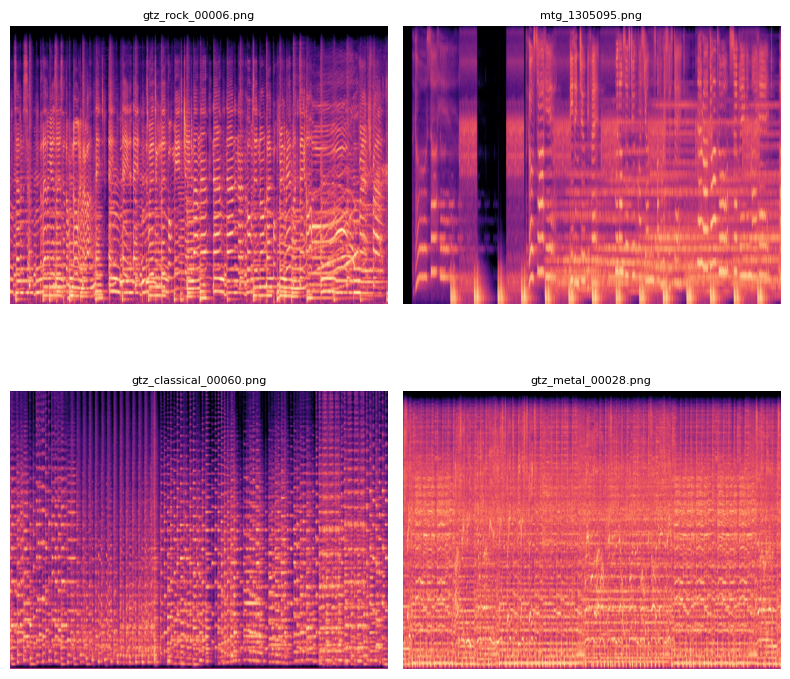

In [6]:
all_images = []

for genre in os.listdir(folder):
    genre_path = os.path.join(folder, genre)

    if os.path.isdir(genre_path):
        for f in os.listdir(genre_path):
            if f.lower().endswith('.png'):
                all_images.append(os.path.join(genre_path, f))

sample_images = random.sample(all_images, 4)


plt.figure(figsize=(8, 8))

for i, img_path in enumerate(sample_images):
    img = Image.open(img_path)

    plt.subplot(2, 2, i+1)
    plt.imshow(img)
    plt.title(os.path.basename(img_path), fontsize=8)
    plt.axis('off')

plt.tight_layout()
plt.show()

In [7]:
img = Image.open(img_path)
img_array = np.array(img)

print("type:", type(img))
print("array type:", type(img_array))
print("shape:", img_array.shape)

type: <class 'PIL.PngImagePlugin.PngImageFile'>
array type: <class 'numpy.ndarray'>
shape: (900, 1220, 4)


## UMAP

**UMap of pixel-level features**:

Total images: 4199
Unique genres: 7


Loading images: 100%|██████████| 4199/4199 [01:31<00:00, 45.91it/s]


Feature shape: (4199, 16384)


/home/giod/miniforge3/envs/cs209b_project/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP shape: (4199, 2)


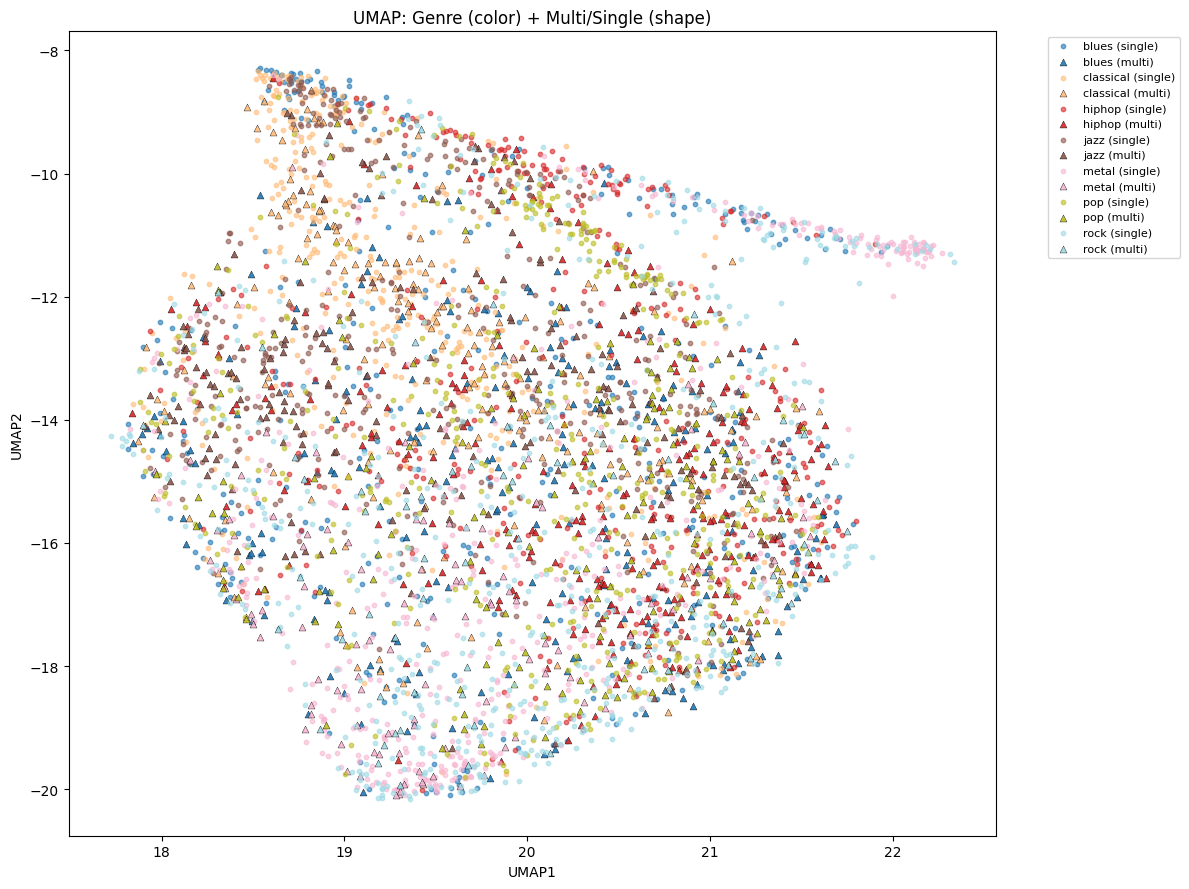

In [8]:
IMAGE_SIZE = (128, 128)
MAX_SAMPLES = 2000
RANDOM_SEED = 1090

UMAP_N_NEIGHBORS = 70
UMAP_MIN_DIST = 0.2
USE_PCA_PREPROCESS = True

random.seed(RANDOM_SEED)

primary_df = pd.read_csv(csv_file)
primary_df["MTG_ID"] = primary_df["TRACK_ID"].str.replace("track_", "mtg_", regex=False)
mtg_lookup = dict(zip(primary_df["MTG_ID"], primary_df["MULTIGENRE"]))


images = []
labels = []
multi_labels = []

for root, _, files in os.walk(folder):
    for file in files:
        if file.lower().endswith(".png"):
            path = os.path.join(root, file)
            name = file.replace(".png", "")

            images.append(path)
            labels.append(os.path.basename(root))

            if name.startswith("mtg_"):
                multi_labels.append(mtg_lookup.get(name, 0))
            else:
                multi_labels.append(0)

images = np.array(images)
labels = np.array(labels)
multi_labels = np.array(multi_labels)

print("Total images:", len(images))
print("Unique genres:", len(set(labels)))


def load_image_vector(path, size=IMAGE_SIZE):
    img = Image.open(path).convert("L")
    img = img.resize(size, Image.BILINEAR)
    arr = np.asarray(img, dtype=np.float32) / 255.0
    return arr.ravel()


X = []
for p in tqdm(images, desc="Loading images"):
    X.append(load_image_vector(p))

X = np.array(X)

print("Feature shape:", X.shape)

Xs = StandardScaler().fit_transform(X)


if USE_PCA_PREPROCESS:
    X_pre = PCA(n_components=50, random_state=RANDOM_SEED).fit_transform(Xs)
else:
    X_pre = Xs


X_umap = umap.UMAP(
    n_neighbors=UMAP_N_NEIGHBORS,
    min_dist=UMAP_MIN_DIST,
    random_state=RANDOM_SEED
).fit_transform(X_pre)

print("UMAP shape:", X_umap.shape)



unique_genres = np.unique(labels)
colors = plt.cm.tab20(np.linspace(0, 1, len(unique_genres)))
genre_color_map = dict(zip(unique_genres, colors))

plt.figure(figsize=(12, 9))

for genre in unique_genres:
    genre_idx = (labels == genre)

    single_idx = genre_idx & (multi_labels == 0)
    multi_idx = genre_idx & (multi_labels == 1)

    color = genre_color_map[genre]

    plt.scatter(
        X_umap[single_idx, 0],
        X_umap[single_idx, 1],
        s=10,
        alpha=0.6,
        c=[color],
        marker='o',
        label=f"{genre} (single)" if np.sum(single_idx) > 0 else None
    )

    plt.scatter(
        X_umap[multi_idx, 0],
        X_umap[multi_idx, 1],
        s=25,
        alpha=0.9,
        c=[color],
        marker='^',
        edgecolor='black',
        linewidth=0.3,
        label=f"{genre} (multi)" if np.sum(multi_idx) > 0 else None
    )

plt.title("UMAP: Genre (color) + Multi/Single (shape)")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")

plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

**UMAP of features extracted by a ResNet-based model**

Successfully loaded MS3 model weights
Feature shape: (420, 2048)


/home/giod/miniforge3/envs/cs209b_project/lib/python3.14/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP shape: (420, 2)


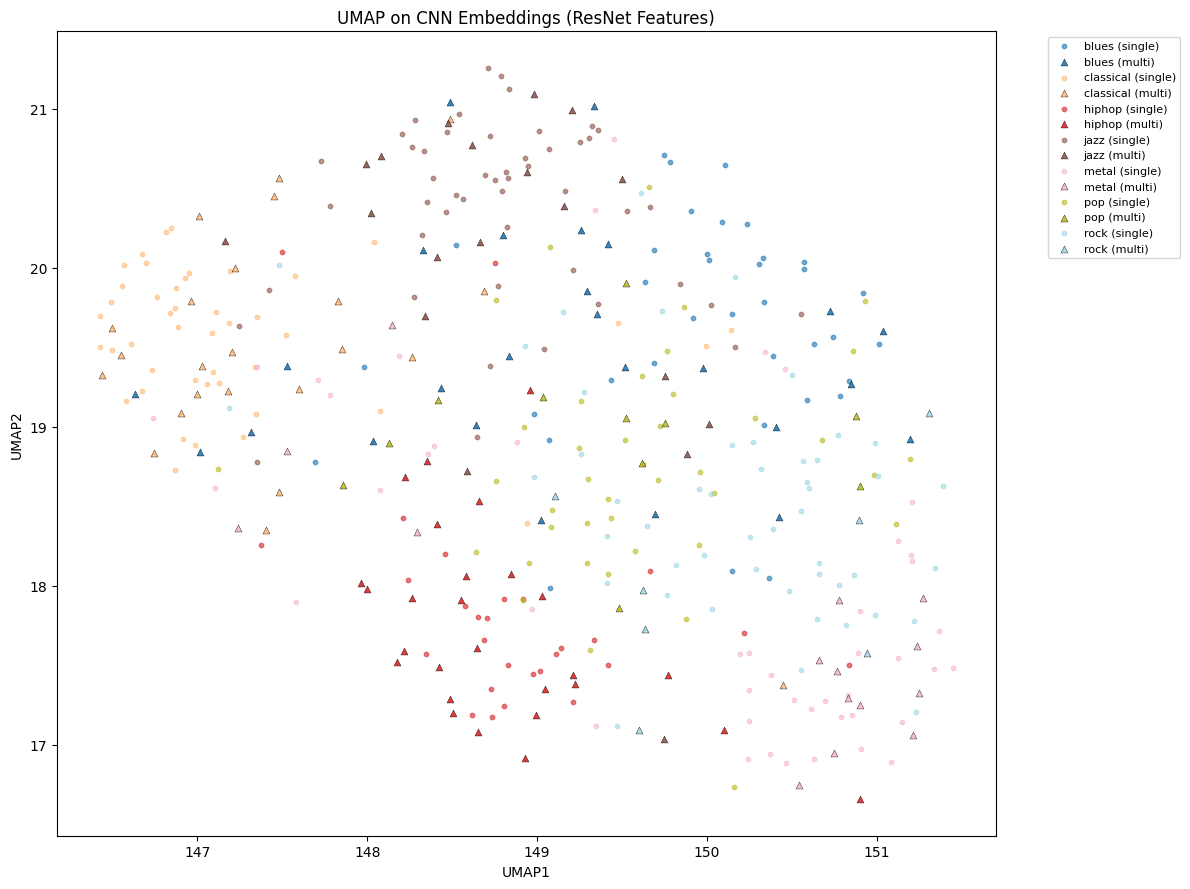

In [9]:
MAX_SAMPLES = 2000
RANDOM_SEED = 1090
UMAP_N_NEIGHBORS = 70
UMAP_MIN_DIST = 0.2
USE_PCA = True

merged_ds = datasets.ImageFolder('Data/dataset_merged') #No transform for batching/augmenting technique below
ms3_model_path = model_path = "models/resnet_model_4.19/best_model_split_l2_3layer_py_aug.pt"

model_ms3 = CustomResNet().to(DEVICE)
if os.path.exists(model_path):
  state_dict = torch.load(model_path)
  model_ms3.load_state_dict(state_dict)
  print("Successfully loaded MS3 model weights")

seed = torch.Generator().manual_seed(109)
train_size = int(0.9 * len(merged_ds))
val_size = len(merged_ds) - train_size

_, val_subset = random_split(merged_ds, [train_size, val_size], generator=seed)

val_dataset_ms3 = MultiVerticalChunkDataset(
  val_subset,
  transform=resnet_transform_val,
  chunk_width=700,
  num_chunks=3
)

val_loader_ms3 = DataLoader(val_dataset_ms3, batch_size=64, shuffle=False, num_workers=2)


np.random.seed(RANDOM_SEED)

# collect filenames + labels from validation set
base_ds = val_dataset_ms3.subset.dataset
val_indices = val_dataset_ms3.subset.indices
val_filenames = [base_ds.samples[i][0] for i in val_indices]

labels = []
multi_labels = []

for fname in val_filenames:
    genre = fname.split('/')[-2]
    labels.append(genre)

    if 'mtg_' in fname:
        mtg_id = fname.split('/')[-1].replace('.png', '')
        row = primary_df.loc[primary_df['MTG_ID'] == mtg_id]
        if len(row) > 0:
            multi_labels.append(int(row.iloc[0]['MULTIGENRE']))
        else:
            multi_labels.append(0)
    else:
        multi_labels.append(0)

labels = np.array(labels)
multi_labels = np.array(multi_labels)

# Extract CNN Embeddings
model_ms3.eval()
features = []

with torch.no_grad():
    for inputs, _ in val_loader_ms3:
        # inputs: (B, N, C, H, W)
        inputs = inputs.to(DEVICE)
        B, N, C, H, W = inputs.shape

        inputs = inputs.view(B * N, C, H, W)

        x = model_ms3.resnet.conv1(inputs)
        x = model_ms3.resnet.bn1(x)
        x = model_ms3.resnet.relu(x)
        x = model_ms3.resnet.maxpool(x)

        x = model_ms3.resnet.layer1(x)
        x = model_ms3.resnet.layer2(x)
        x = model_ms3.resnet.layer3(x)
        x = model_ms3.resnet.layer4(x)

        x = model_ms3.resnet.avgpool(x)
        x = torch.flatten(x, 1)  # (B*N, 2048)

        x = x.view(B, N, -1).mean(dim=1)  # average chunks → (B, 2048)

        features.append(x.cpu().numpy())

X = np.vstack(features)

# subsampling for speed
if len(X) > MAX_SAMPLES:
    idx = np.random.choice(len(X), MAX_SAMPLES, replace=False)
    X = X[idx]
    labels = labels[idx]
    multi_labels = multi_labels[idx]

print("Feature shape:", X.shape)

# scale and PCA
Xs = StandardScaler().fit_transform(X)

if USE_PCA:
    X_pre = PCA(n_components=50, random_state=RANDOM_SEED).fit_transform(Xs)
else:
    X_pre = Xs

# UMAP
X_umap = umap.UMAP(
    n_neighbors=UMAP_N_NEIGHBORS,
    min_dist=UMAP_MIN_DIST,
    random_state=RANDOM_SEED
).fit_transform(X_pre)

print("UMAP shape:", X_umap.shape)

# Plot
unique_genres = np.unique(labels)
colors = plt.cm.tab20(np.linspace(0, 1, len(unique_genres)))
genre_color_map = dict(zip(unique_genres, colors))

plt.figure(figsize=(12, 9))

for genre in unique_genres:
    genre_idx = (labels == genre)

    single_idx = genre_idx & (multi_labels == 0)
    multi_idx = genre_idx & (multi_labels == 1)

    color = genre_color_map[genre]

    plt.scatter(
        X_umap[single_idx, 0],
        X_umap[single_idx, 1],
        s=10,
        alpha=0.6,
        c=[color],
        marker='o',
        label=f"{genre} (single)" if np.sum(single_idx) > 0 else None
    )

    plt.scatter(
        X_umap[multi_idx, 0],
        X_umap[multi_idx, 1],
        s=25,
        alpha=0.9,
        c=[color],
        marker='^',
        edgecolor='black',
        linewidth=0.3,
        label=f"{genre} (multi)" if np.sum(multi_idx) > 0 else None
    )

plt.title("UMAP on CNN Embeddings (ResNet Features)")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")

plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

# Pipeline & Model Training

Our pipeline is depicted below and justified in greater depth in our written report. Below is the code used to initialize and train our final model; the code used to train other forms of the model may be found in the zipped `utils` folder. Because of the high computational cost of training ViT-based models, we have included the full training loop, but preferntially loaded the model.

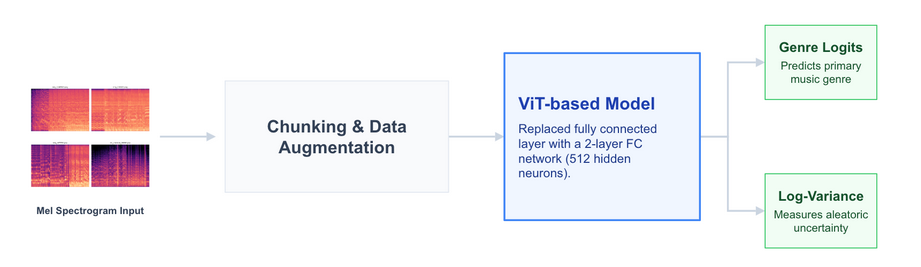

In [10]:
class SpecAugmentBands:
    """
    Apply simple spectrogram-specific augmentation:
    - frequency masking: masks horizontal bands
    - time masking: masks vertical bands

    Expects a tensor of shape (C, H, W).
    """
    def __init__(
        self,
        freq_mask_param=16,
        time_mask_param=24,
        num_freq_masks=2,
        num_time_masks=2,
        p=0.5
    ):
        self.freq_mask_param = freq_mask_param
        self.time_mask_param = time_mask_param
        self.num_freq_masks = num_freq_masks
        self.num_time_masks = num_time_masks
        self.p = p

    def __call__(self, x):
        if random.random() > self.p:
            return x

        _, H, W = x.shape

        # Frequency masking: mask along height
        for _ in range(self.num_freq_masks):
            mask_h = random.randint(0, self.freq_mask_param)
            if mask_h > 0 and mask_h < H:
                top = random.randint(0, H - mask_h)
                x[:, top:top + mask_h, :] = 0

        # Time masking: mask along width
        for _ in range(self.num_time_masks):
            mask_w = random.randint(0, self.time_mask_param)
            if mask_w > 0 and mask_w < W:
                left = random.randint(0, W - mask_w)
                x[:, :, left:left + mask_w] = 0

        return x


vit_transform_val = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5]),
])

vit_transform_train = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomAffine(degrees=0, translate=(0.05, 0.02), scale=(0.95, 1.05)),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    SpecAugmentBands(
        freq_mask_param=16,
        time_mask_param=24,
        num_freq_masks=2,
        num_time_masks=2,
        p=0.6
    ),
    #transforms.RandomErasing(p=0.4, scale=(0.02, 0.1), ratio=(0.3, 3.3)),
    transforms.Normalize(mean=[0.5, 0.5, 0.5],
                         std=[0.5, 0.5, 0.5]),
])

class UncertaintyAwareViT(nn.Module):
    def __init__(self, model_name, num_labels, id2label=None, label2id=None):
        super().__init__()

        self.vit = ViTModel.from_pretrained(model_name)
        hidden_size = self.vit.config.hidden_size

        self.num_labels = num_labels
        self.id2label = id2label
        self.label2id = label2id

        self.head = nn.Sequential(
            nn.LayerNorm(hidden_size),
            nn.Linear(hidden_size, 512),
            nn.GELU(),
            nn.Dropout(0.3),
        )

        # f_i in eq. 10
        self.logits_head = nn.Linear(512, num_labels)

        # log sigma_i, one uncertainty value per class-logit
        self.log_sigma_head = nn.Linear(512, num_labels)

    def forward(self, pixel_values):
        outputs = self.vit(pixel_values=pixel_values)
        cls = outputs.last_hidden_state[:, 0]

        h = self.head(cls)

        logits = self.logits_head(h)
        log_sigma = self.log_sigma_head(h).clamp(-5, 3)

        sigma = torch.exp(log_sigma)

        return logits, sigma
    
class HeteroscedasticClassificationLoss(nn.Module):
    """
    Implements Kendall & Gal classification loss, eqs. 10-12.

    logits: (B, C)
    sigma:  (B, C)
    targets: (B,)
    """
    def __init__(self, num_samples=20, label_smoothing=0.0):
        super().__init__()
        self.num_samples = num_samples
        self.label_smoothing = label_smoothing

    def forward(self, logits, sigma, targets):
        B, C = logits.shape
        T = self.num_samples

        eps = torch.randn(T, B, C, device=logits.device, dtype=logits.dtype)

        # x_hat_{i,t} = f_i + sigma_i * epsilon_t
        noisy_logits = logits.unsqueeze(0) + sigma.unsqueeze(0) * eps

        log_probs = F.log_softmax(noisy_logits, dim=-1)  # (T, B, C)

        if self.label_smoothing > 0:
            with torch.no_grad():
                target_dist = torch.zeros(B, C, device=logits.device)
                target_dist.fill_(self.label_smoothing / (C - 1))
                target_dist.scatter_(1, targets.unsqueeze(1), 1.0 - self.label_smoothing)

            sample_log_likelihood = (log_probs * target_dist.unsqueeze(0)).sum(dim=-1)
        else:
            sample_log_likelihood = log_probs[:, torch.arange(B, device=logits.device), targets]

        # - log mean_t exp(log p_t)
        loss = -torch.logsumexp(sample_log_likelihood, dim=0) + torch.log(
            torch.tensor(T, device=logits.device, dtype=logits.dtype)
        )

        return loss.mean()

def compute_metrics(pred):
    preds = pred.predictions.argmax(axis=1)
    return {"accuracy": accuracy_score(pred.label_ids, preds)}

In [11]:
#Labels for ViT-type models
labels = merged_ds.classes
label2id = merged_ds.class_to_idx
id2label = {idx: label for label, idx in label2id.items()}

train_subset, val_subset = random_split(merged_ds, [train_size, val_size], generator=seed)

#Because we will only be doing forward evaluation on the train DS, we use the same method as for the val dataset here
train_dataset_vit = MultiVerticalChunkDataset(
    train_subset,
    transform=vit_transform_val,
    chunk_width=700,
    num_chunks=5
)

val_dataset_vit = MultiVerticalChunkDataset(
    val_subset,
    transform=vit_transform_val,
    chunk_width=700,
    num_chunks=5
)

train_loader_vit = DataLoader(train_dataset_vit, batch_size=64, shuffle=True, num_workers=2)
val_loader_vit = DataLoader(val_dataset_vit, batch_size=64, shuffle=False, num_workers=2)

vit_model_uncert = UncertaintyAwareViT(
    model_name="google/vit-base-patch16-224",
    num_labels=len(labels),
    id2label=id2label,
    label2id=label2id
)

Loading weights: 100%|██████████| 198/198 [00:00<00:00, 13720.24it/s]
ViTModel LOAD REPORT from: google/vit-base-patch16-224
Key                 | Status     | 
--------------------+------------+-
classifier.weight   | UNEXPECTED | 
classifier.bias     | UNEXPECTED | 
pooler.dense.weight | MISSING    | 
pooler.dense.bias   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


In [12]:
vit_uncert_path = 'models/vit_uncert_aware/best_model_vit-224_uncert.pt'

if os.path.exists(vit_uncert_path):
    vit_model_state = torch.load('models/vit_uncert_aware/best_model_vit-224_uncert.pt')
    vit_model_uncert.load_state_dict(vit_model_state)

else:
    set_seed(SEED)
    
    # merged_ds = datasets.ImageFolder('dataset_merged', transforms.ToTensor()) #Uncomment for basic transform
    merged_ds = datasets.ImageFolder('dataset_merged') #Uncomment for resnet transform
    
    #train-val split
    seed = torch.Generator().manual_seed(109)
    train_size = int(0.9 * len(merged_ds))
    val_size = len(merged_ds) - train_size

    labels = merged_ds.classes
    label2id = merged_ds.class_to_idx
    id2label = {idx: label for label, idx in label2id.items()}
    
    train_subset, val_subset = random_split(merged_ds, [train_size, val_size], generator=seed)

    train_dataset = RandomVerticalChunkDataset(
    train_subset,
    transform=vit_transform_train,
    chunk_width=700
    )
    
    val_dataset = MultiVerticalChunkDataset(
        val_subset,
        transform=vit_transform_val,
        chunk_width=700,
        num_chunks=5
    )
    
    train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, num_workers=2)
    val_loader = DataLoader(val_dataset, batch_size=64, shuffle=False, num_workers=2)
    
    
    model = UncertaintyAwareViT(
        model_name="google/vit-base-patch16-224",
        num_labels=len(labels),
        id2label=id2label,
        label2id=label2id
    ).to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=2e-5,
        weight_decay=0.01
    )

    criterion = HeteroscedasticClassificationLoss(
        num_samples=20,
        label_smoothing=0.1
    )

    save_dir = 'models/vit_uncert_aware'
    
    if not os.path.exists(save_dir):
        os.makedirs(save_dir)

    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=2
    )

    patience = 5
    epochs_without_improvement = 0
    epoch = 0

    best_val_loss = float("inf")
    best_model_wts = copy.deepcopy(model.state_dict())

    training_hist = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc_det": [],
        "val_acc_noisy": [],
    }

    while epochs_without_improvement < patience:
        epoch += 1

        # -----------------
        # Training
        # -----------------
        model.train()

        running_train_loss = 0.0
        running_train_correct = 0
        running_train_total = 0

        for inputs, target_labels in train_loader:
            inputs = inputs.to(DEVICE)
            target_labels = target_labels.to(DEVICE)

            optimizer.zero_grad()

            logits, sigma = model(pixel_values=inputs)
            loss = criterion(logits, sigma, target_labels)

            loss.backward()
            optimizer.step()

            running_train_loss += loss.item() * inputs.size(0)

            preds = logits.argmax(dim=1)
            running_train_correct += (preds == target_labels).sum().item()
            running_train_total += target_labels.size(0)

        epoch_train_loss = running_train_loss / running_train_total
        epoch_train_acc = running_train_correct / running_train_total

        # -----------------
        # Validation
        # -----------------
        model.eval()

        running_val_loss = 0.0
        running_val_correct = 0
        running_val_total = 0
        running_val_noisy_correct = 0
        running_val_noisy_total = 0

        with torch.no_grad():
            for inputs, target_labels in val_loader:
                # inputs: (B, N, C, H, W)
                inputs = inputs.to(DEVICE)
                target_labels = target_labels.to(DEVICE)

                batch_size, num_chunks, C, H, W = inputs.shape

                inputs = inputs.view(batch_size * num_chunks, C, H, W)

                logits, sigma = model(pixel_values=inputs)

                #Average outputs
                logits = logits.view(batch_size, num_chunks, -1).mean(dim=1)
                sigma = sigma.view(batch_size, num_chunks, -1).mean(dim=1)

                loss = criterion(logits, sigma, target_labels)

                running_val_loss += loss.item() * batch_size

                #Logit-only val acc

                preds = logits.argmax(dim=1)

                running_val_correct += (preds == target_labels).sum().item()
                running_val_total += batch_size

                # noisy / uncertainty-aware validation accuracy
                T = 50
                B, C = logits.shape

                eps = torch.randn(T, B, C, device=logits.device, dtype=logits.dtype)
                noisy_logits = logits.unsqueeze(0) + sigma.unsqueeze(0) * eps

                noisy_probs = F.softmax(noisy_logits, dim=-1).mean(dim=0)
                noisy_preds = noisy_probs.argmax(dim=1)

                running_val_noisy_correct += (noisy_preds == target_labels).sum().item()
                running_val_noisy_total += batch_size

        epoch_val_loss = running_val_loss / running_val_total
        epoch_val_acc = running_val_correct / running_val_total
        epoch_val_noisy_acc = running_val_noisy_correct / running_val_noisy_total

        scheduler.step(epoch_val_loss)

        training_hist["train_loss"].append(epoch_train_loss)
        training_hist["train_acc"].append(epoch_train_acc)
        training_hist["val_loss"].append(epoch_val_loss)
        training_hist["val_acc_det"].append(epoch_val_acc)
        training_hist["val_acc_noisy"].append(epoch_val_noisy_acc)

        current_lr = optimizer.param_groups[0]["lr"]

        print(
            f"Epoch {epoch} | "
            f"LR: {current_lr:.6g} | "
            f"Train Loss: {epoch_train_loss:.4f} | "
            f"Train Acc: {epoch_train_acc:.4f} | "
            f"Val Loss: {epoch_val_loss:.4f} | "
            f"Val Acc (Logit-only): {epoch_val_acc:.4f} | "
            f"Val Acc (Uncertainty-aware): {epoch_val_noisy_acc:.4f}"
        )

        # -----------------
        # Early stopping
        # -----------------
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            epochs_without_improvement = 0
            best_model_wts = copy.deepcopy(model.state_dict())

            torch.save(
                best_model_wts,
                os.path.join(save_dir, "best_model_vit-224_uncert.pt")
            )

            with open(os.path.join(save_dir, "training_hist_vit-224_uncert.json"), "w") as f:
                json.dump(training_hist, f, indent=4)

        else:
            epochs_without_improvement += 1
            print(
                f"No improvement for "
                f"{epochs_without_improvement}/{patience} epoch(s)."
            )

    model.load_state_dict(best_model_wts)

    with open(os.path.join(save_dir, "training_hist_vit-224_uncert.json"), "w") as f:
        json.dump(training_hist, f, indent=4)

# Model error and uncertainty analysis
## Training histories

Below we graphically represent the training histories for our final ResNet and ViT models that do _not_ take into account uncertainty and for our uncertainty-aware models.

In [13]:
def plot_histories(losses, loss_labels, accs, acc_labels, model_type):
    epochs = range(1, len(losses[0]) + 1)


    plt.figure(figsize=(10, 4))

    plt.subplot(1, 2, 1)
    for l, l_lab in zip(losses, loss_labels):
        plt.plot(epochs, l, label=l_lab)
    plt.title(f"Loss history of {model_type}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid()

    plt.subplot(1, 2, 2)
    for a, a_lab in zip(accs, acc_labels):
        plt.plot(epochs, a, label=a_lab)
    plt.title(f"Accuracy history of {model_type}")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.grid()

    plt.tight_layout()
    plt.show()

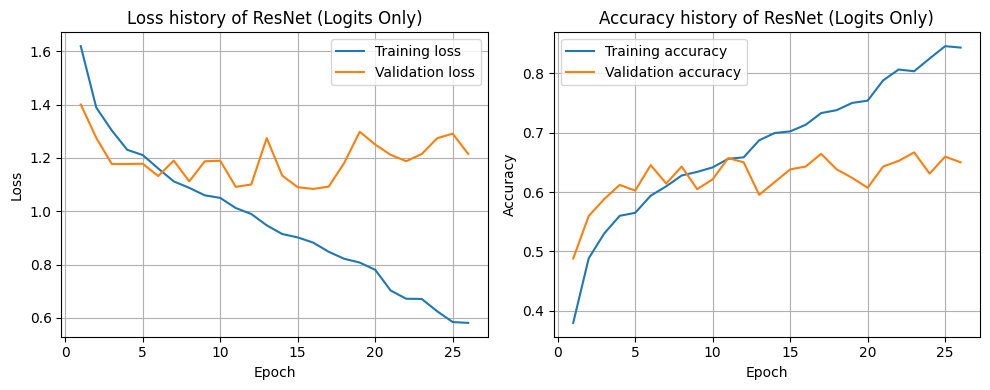

In [14]:
with open('models/resnet/training_hist_varwidth_morechunks_ls03.json') as f:
    vit_th = json.load(f)

plot_histories(
    [vit_th['train_loss'], vit_th['val_loss']],
    ['Training loss', 'Validation loss'],
    [vit_th['train_acc'], vit_th['val_acc']],
    ['Training accuracy', 'Validation accuracy'],
    'ResNet (Logits Only)'
)

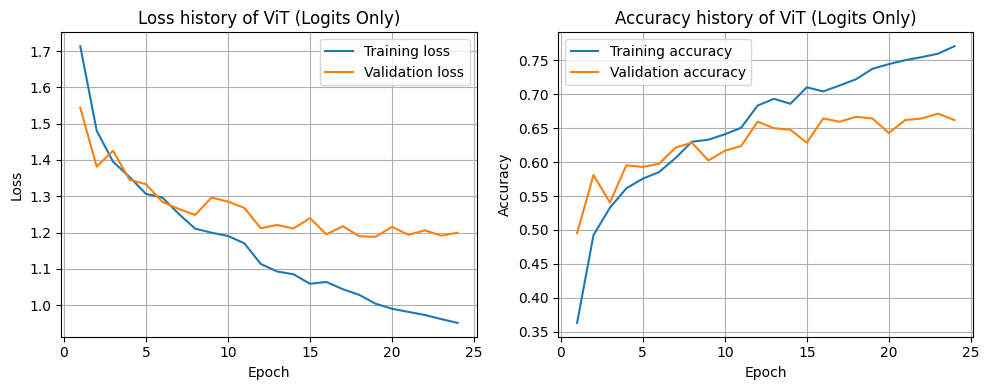

In [15]:
with open('models/vit/training_hist_vit.json') as f:
    vit_th = json.load(f)

plot_histories(
    [vit_th['train_loss'], vit_th['val_loss']],
    ['Training loss', 'Validation loss'],
    [vit_th['train_acc'], vit_th['val_acc']],
    ['Training accuracy', 'Validation accuracy'],
    'ViT (Logits Only)'
)

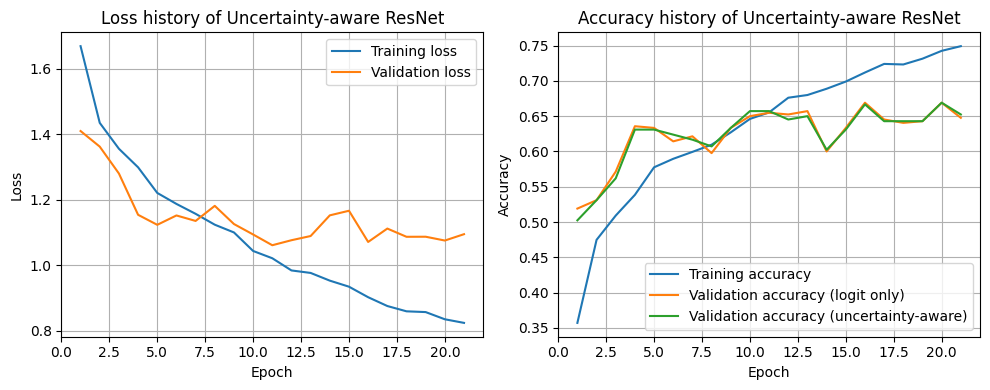

In [16]:
with open('models/resnet_uncert_aware/training_hist_resnet_uncert.json') as f:
    rn_uncert_th = json.load(f)

plot_histories(
    [rn_uncert_th['train_loss'], rn_uncert_th['val_loss']],
    ['Training loss', 'Validation loss'],
    [rn_uncert_th['train_acc'], rn_uncert_th['val_acc_det'], rn_uncert_th['val_acc_noisy']],
    ['Training accuracy', 'Validation accuracy (logit only)', 'Validation accuracy (uncertainty-aware)'],
    'Uncertainty-aware ResNet'
)

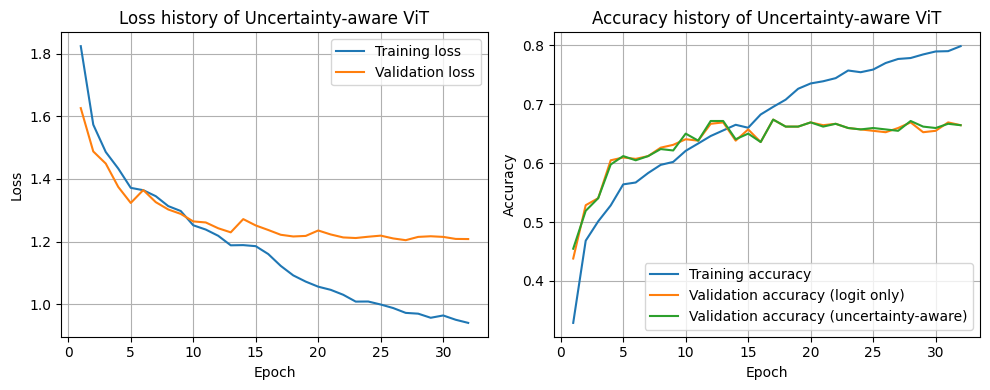

In [17]:
with open('models/vit_uncert_aware/training_hist_vit-224_uncert.json') as f:
    vit_uncert_th = json.load(f)

plot_histories(
    [vit_uncert_th['train_loss'], vit_uncert_th['val_loss']],
    ['Training loss', 'Validation loss'],
    [vit_uncert_th['train_acc'], vit_uncert_th['val_acc_det'], vit_uncert_th['val_acc_noisy']],
    ['Training accuracy', 'Validation accuracy (logit only)', 'Validation accuracy (uncertainty-aware)'],
    'Uncertainty-aware ViT'
)

## Error analysis
Below we produce a final error analysis of our uncertainty-aware ViT and CNN models. We focus on the behavior of the models (when uncertainty is taken into account) in misclassifying the genre of mel spectrograms in relation to their multigenre status.

In [18]:
train_dataset_rn = MultiVerticalChunkDataset(
    train_subset,
    transform=resnet_transform_val,
    chunk_width=700,
    num_chunks=5
)

val_dataset_rn = MultiVerticalChunkDataset(
    val_subset,
    transform=resnet_transform_val,
    chunk_width=600,
    num_chunks=5
)

train_loader_rn = DataLoader(train_dataset_rn, batch_size=64, shuffle=True, num_workers=2)
val_loader_rn = DataLoader(val_dataset_rn, batch_size=64, shuffle=False, num_workers=2)

In [19]:
#Load rn model

rn_model_uncert = UncertAwareResNet()
rn_model_state = torch.load('models/resnet_uncert_aware/best_model_resnet_uncert.pt')
rn_model_uncert.load_state_dict(rn_model_state)

<All keys matched successfully>

In [20]:
# Run inference on val sets

rn_raw_logits = []
rn_sigmas = []
rn_final_probs = []
rn_preds = []

rn_model_uncert = rn_model_uncert.to(DEVICE)

with torch.no_grad():
    for inputs, labels in val_loader_rn:
        # inputs: (B, N, C, H, W)
        labels = labels.to(DEVICE)
        inputs = inputs.to(DEVICE)

        batch_size, num_chunks, C, H, W = inputs.shape

        inputs = inputs.view(batch_size * num_chunks, C, H, W)
        logits, sigma = rn_model_uncert(inputs)

        #Average outputs
        logits = logits.view(batch_size, num_chunks, -1).mean(dim=1)
        sigma = sigma.view(batch_size, num_chunks, -1).mean(dim=1)

        rn_raw_logits.append(logits)
        rn_sigmas.append(sigma)

        # noisy / uncertainty-aware validation accuracy
        T = 50
        B, C = logits.shape

        eps = torch.randn(T, B, C, device=logits.device, dtype=logits.dtype)
        noisy_logits = logits.unsqueeze(0) + sigma.unsqueeze(0) * eps

        noisy_probs = F.softmax(noisy_logits, dim=-1).mean(dim=0)
        rn_final_probs.append(noisy_probs)
        noisy_preds = noisy_probs.argmax(dim=1)
        rn_preds.append(noisy_preds)

rn_raw_logits = torch.concat(rn_raw_logits).cpu()
rn_sigmas = torch.concat(rn_sigmas).cpu()
rn_final_probs = torch.concat(rn_final_probs).cpu()
rn_preds = torch.concat(rn_preds).cpu()

In [21]:
torch.cuda.empty_cache()
vit_model_uncert = vit_model_uncert.to(DEVICE)

vit_raw_logits = []
vit_sigmas = []
vit_final_probs = []
vit_preds = []


with torch.no_grad():
    for inputs, labels in val_loader_vit:
        # inputs: (B, N, C, H, W)
        labels = labels.to(DEVICE)
        inputs = inputs.to(DEVICE)

        batch_size, num_chunks, C, H, W = inputs.shape

        inputs = inputs.view(batch_size * num_chunks, C, H, W)
        logits, sigma = vit_model_uncert(inputs)

        #Average outputs
        logits = logits.view(batch_size, num_chunks, -1).mean(dim=1)
        sigma = sigma.view(batch_size, num_chunks, -1).mean(dim=1)

        vit_raw_logits.append(logits)
        vit_sigmas.append(sigma)

        # noisy / uncertainty-aware validation accuracy
        T = 50
        B, C = logits.shape

        eps = torch.randn(T, B, C, device=logits.device, dtype=logits.dtype)
        noisy_logits = logits.unsqueeze(0) + sigma.unsqueeze(0) * eps

        noisy_probs = F.softmax(noisy_logits, dim=-1).mean(dim=0)
        vit_final_probs.append(noisy_probs)
        noisy_preds = noisy_probs.argmax(dim=1)
        vit_preds.append(noisy_preds)

vit_raw_logits = torch.concat(vit_raw_logits).cpu()
vit_sigmas = torch.concat(vit_sigmas).cpu()
vit_final_probs = torch.concat(vit_final_probs).cpu()
vit_preds = torch.concat(vit_preds).cpu()

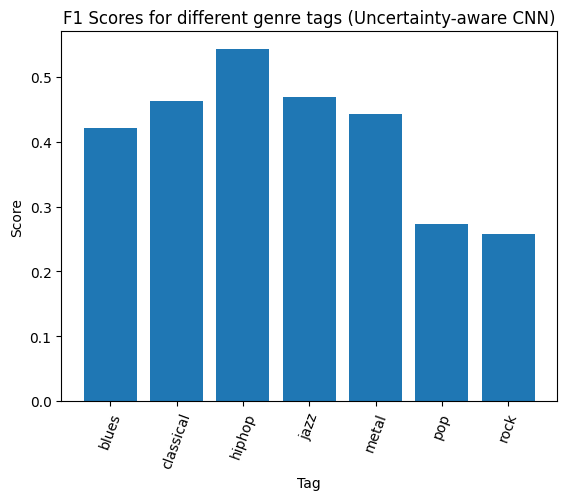

In [22]:
y_true = [a[1] for a in val_dataset_rn]
f1_scores_rn = f1_score(y_true, rn_preds, average=None)

idx_to_class = {v:k for k, v in merged_ds.class_to_idx.items()}

plt.bar([idx_to_class[a] for a in range(0, f1_scores_rn.shape[0])], f1_scores_rn)
plt.xticks(rotation=70)
plt.xlabel("Tag")
plt.ylabel("Score")
plt.title("F1 Scores for different genre tags (Uncertainty-aware CNN)");

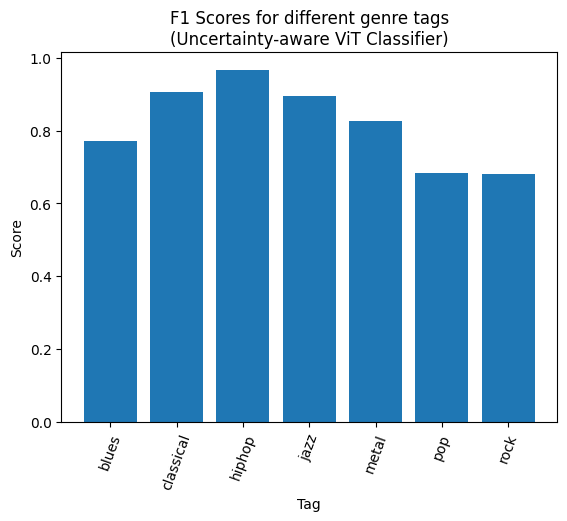

In [23]:
y_true = [a[1] for a in val_dataset_vit]
f1_scores_vit = f1_score(y_true, vit_preds, average=None)

idx_to_class = {v:k for k, v in merged_ds.class_to_idx.items()}

plt.bar([idx_to_class[a] for a in range(0, f1_scores_vit.shape[0])], f1_scores_vit)
plt.xticks(rotation=70)
plt.xlabel("Tag")
plt.ylabel("Score")
plt.title("F1 Scores for different genre tags\n(Uncertainty-aware ViT Classifier)");

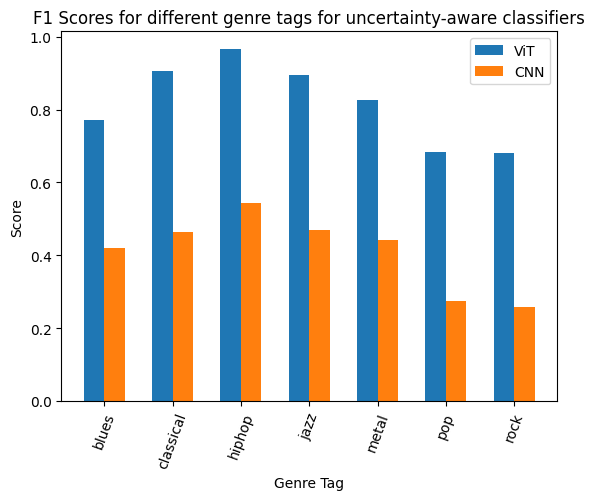

In [24]:
width = 0.3
plt.bar([a for a in range(0, f1_scores_vit.shape[0])], f1_scores_vit, width, label="ViT")
plt.bar([a+width for a in range(0, f1_scores_rn.shape[0])], f1_scores_rn, width, label="CNN")


plt.xticks([a+width / 2 for a in range(0, f1_scores_vit.shape[0])], [idx_to_class[a] for a in range(0, f1_scores_vit.shape[0])], rotation=70)
plt.xlabel("Genre Tag")
plt.ylabel("Score")
plt.title("F1 Scores for different genre tags for uncertainty-aware classifiers")
plt.legend();

As the Uncertainty-Aware ViT performs far better in terms of F1 scores, we choose it as our final model and perform all subsequent analysis on it:

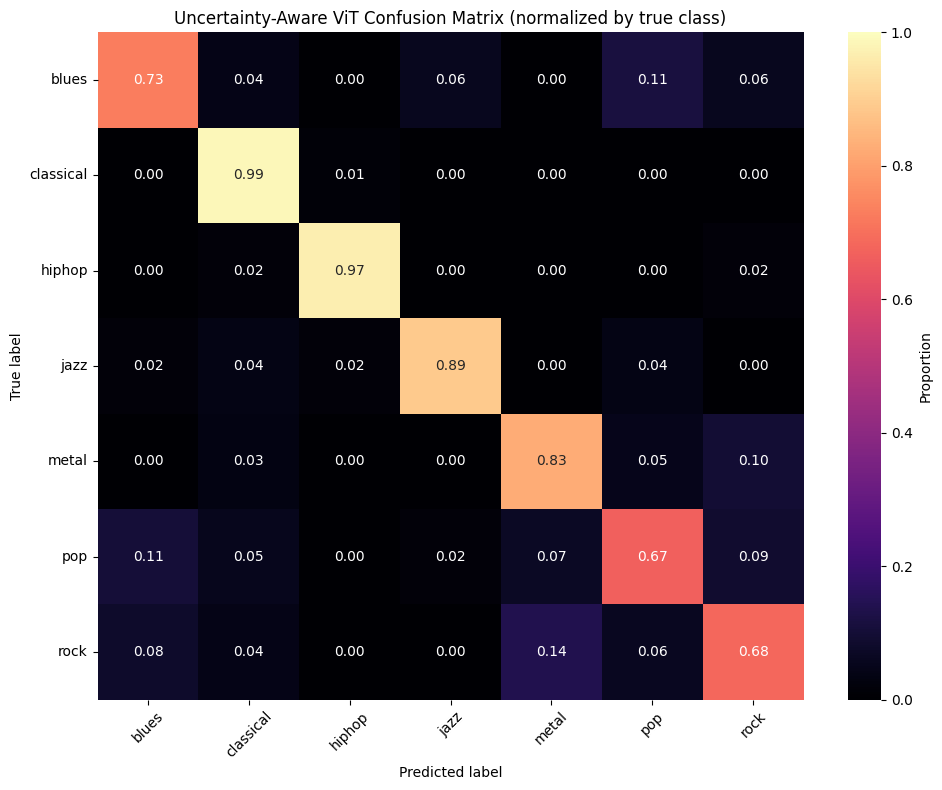

Per-class accuracy (correct / total -> accuracy):
  blues      :  51 /  70  ->  72.86%
  classical  :  67 /  68  ->  98.53%
  hiphop     :  57 /  59  ->  96.61%
  jazz       :  47 /  53  ->  88.68%
  metal      :  52 /  63  ->  82.54%
  pop        :  38 /  57  ->  66.67%
  rock       :  34 /  50  ->  68.00%


In [25]:

# Reconstruct y_true from the validation subset to be safe:
try:
    y_pred = vit_preds.numpy() if isinstance(vit_preds, torch.Tensor) else np.array(vit_preds)
    y_true_arr = np.array(y_true)
except Exception:
    # Fallback: reconstruct from val_subset (works if val_subset is a torch.utils.data.Subset of ImageFolder)
    base_ds = val_subset.dataset
    y_true_arr = np.array([base_ds.targets[i] for i in val_subset.indices])
    y_pred = np.array(vit_preds)

#  Confusion matrix (counts)
cm = confusion_matrix(y_true_arr, y_pred, labels=np.arange(len(merged_ds.classes)))
#  Normalized confusion matrix (rows sum to 1)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
plt.figure(figsize=(10, 8))
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="magma",
            xticklabels=merged_ds.classes, yticklabels=merged_ds.classes,
            vmin=0.0, vmax=1.0, cbar_kws={'label': 'Proportion'})
plt.xlabel("Predicted label")
plt.ylabel("True label")
plt.title("Uncertainty-Aware ViT Confusion Matrix (normalized by true class)")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#  Per-class summary: correct / total / accuracy
print("Per-class accuracy (correct / total -> accuracy):")
for i, cls in enumerate(merged_ds.classes):
    correct = cm[i, i]
    total = cm[i].sum()
    acc = correct / total if total > 0 else 0.0
    print(f"  {cls:10s} : {correct:3d} / {total:3d}  ->  {acc:.2%}")


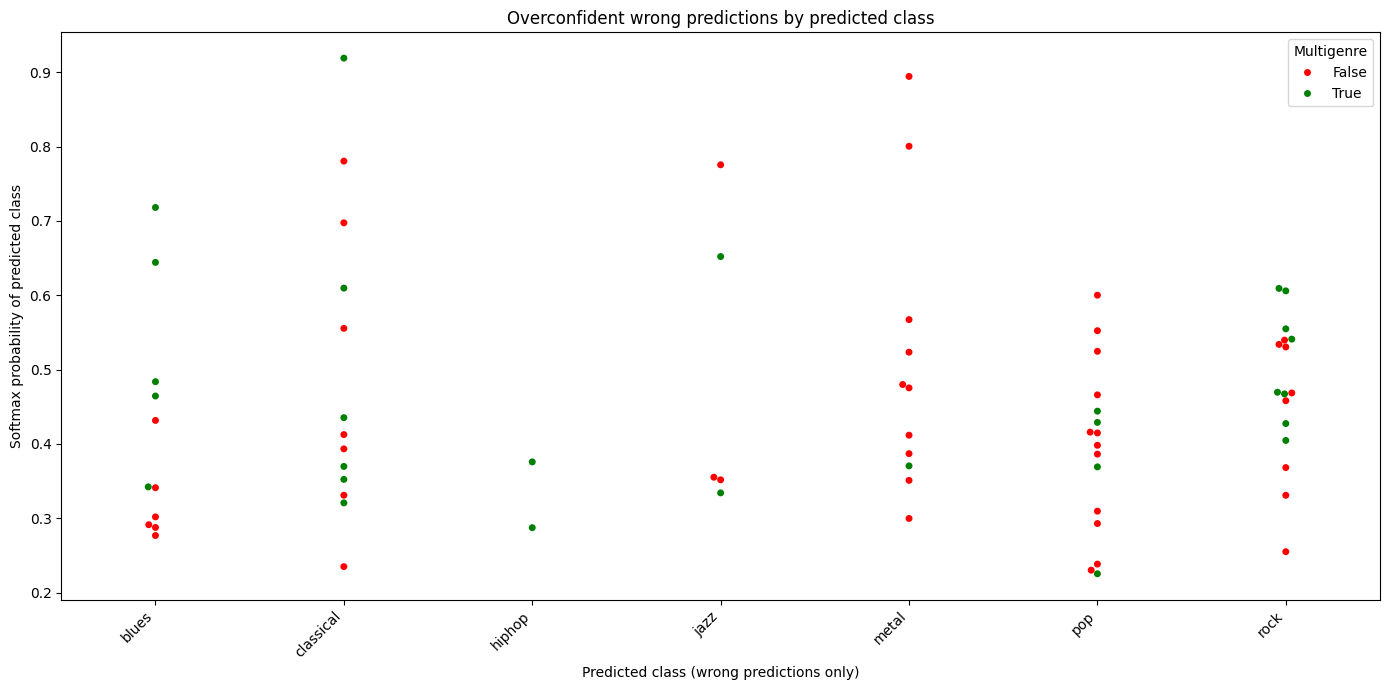

In [26]:
def mtg_id_from_fn(fn):
  return fn.split('/')[-1][:-4]

# base ImageFolder
base_ds = val_dataset_vit.subset.dataset

# indices of validation examples inside merged_ds / ImageFolder
val_indices = val_dataset_vit.subset.indices

# filenames in the exact same order as val_dataset / val_loader (because shuffle=False)
val_filenames = [base_ds.samples[i][0] for i in val_indices]

wrong_by_pred_class = defaultdict(list)

for i in range(len(vit_preds)):
    pred = vit_preds[i].item()
    true = y_true[i]
    prob = vit_final_probs[i, pred].item()
    fname = val_filenames[i]

    if pred != true:

        if 'gtz_' in fname:
          multigenre = False
        else:
          mtg_entry = primary_df.loc[primary_df['MTG_ID'] == mtg_id_from_fn(fname)]
          if len(mtg_entry) > 0:
            mtg_entry = mtg_entry.iloc[0]  # <-- get first row as a Series
            multigenre = bool(mtg_entry['MULTIGENRE'])
          else:
            multigenre = False


        wrong_by_pred_class[pred].append({
            "filename": fname,
            "pred_idx": pred,
            "pred_class": idx_to_class[pred],
            "true_idx": true,
            "true_class": idx_to_class[true],
            "confidence": prob,
            'multigenre': multigenre,
        })

rows = []
for pred_class_idx, items in wrong_by_pred_class.items():
    for item in items:
        rows.append({
            "pred_class": item["pred_class"],
            "confidence": item["confidence"],
            "multigenre": item["multigenre"],
            "true_class": item["true_class"],
            "filename": item["filename"],
        })

wrong_df = pd.DataFrame(rows)

# sort x-axis by class index instead of alphabetically
class_order = [idx_to_class[i] for i in sorted(wrong_by_pred_class.keys())]
class_order = [c for c in class_order if c in wrong_df["pred_class"].unique()]

plt.figure(figsize=(14, 7))

sns.swarmplot(
    data=wrong_df,
    x="pred_class",
    y="confidence",
    hue="multigenre",
    order=class_order,
    palette={False: "red", True: "green"},
    dodge=False,
    size=5,
)

plt.xlabel("Predicted class (wrong predictions only)")
plt.ylabel("Softmax probability of predicted class")
plt.title("Overconfident wrong predictions by predicted class")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Multigenre")
plt.tight_layout()
plt.show()

In [27]:
print(f"Proportion of incorrectly-classified val samples that are multigenre: {wrong_df.value_counts('multigenre')[True]} / {wrong_df.shape[0]} = {wrong_df.value_counts('multigenre')[True]/wrong_df.shape[0]}")

Proportion of incorrectly-classified val samples that are multigenre: 28 / 74 = 0.3783783783783784


## Uncertainty metrics and relationship to multigenre state
For assessing the relationship of uncertainty metrics to multigenre state, we will work with the whole dataset. This constitutes the core of our research question.

In [28]:
vit_raw_logits_tr = []
vit_sigmas_tr = []
vit_final_probs_tr = []
vit_preds_tr = []


with torch.no_grad():
    for inputs, labels in train_loader_vit:
        # inputs: (B, N, C, H, W)
        labels = labels.to(DEVICE)
        inputs = inputs.to(DEVICE)

        batch_size, num_chunks, C, H, W = inputs.shape

        inputs = inputs.view(batch_size * num_chunks, C, H, W)
        logits, sigma = vit_model_uncert(inputs)

        #Average outputs
        logits = logits.view(batch_size, num_chunks, -1).mean(dim=1)
        sigma = sigma.view(batch_size, num_chunks, -1).mean(dim=1)

        vit_raw_logits_tr.append(logits)
        vit_sigmas_tr.append(sigma)

        # noisy / uncertainty-aware validation accuracy
        T = 50
        B, C = logits.shape

        eps = torch.randn(T, B, C, device=logits.device, dtype=logits.dtype)
        noisy_logits = logits.unsqueeze(0) + sigma.unsqueeze(0) * eps

        noisy_probs = F.softmax(noisy_logits, dim=-1).mean(dim=0)
        vit_final_probs_tr.append(noisy_probs)
        noisy_preds = noisy_probs.argmax(dim=1)
        vit_preds_tr.append(noisy_preds)

vit_raw_logits_tr = torch.concat(vit_raw_logits_tr).cpu()
vit_sigmas_tr = torch.concat(vit_sigmas_tr).cpu()
vit_final_probs_tr = torch.concat(vit_final_probs_tr).cpu()
vit_preds_tr = torch.concat(vit_preds_tr).cpu()

vit_raw_logits_full = torch.concat([vit_raw_logits, vit_raw_logits_tr])
vit_sigmas_full = torch.concat([vit_sigmas, vit_sigmas_tr])
vit_final_probs_full = torch.concat([vit_final_probs, vit_final_probs_tr])
vit_preds_full = torch.concat([vit_preds, vit_preds_tr])


In [29]:
y_true += [a[1] for a in train_dataset_vit]

train_indices = train_dataset_vit.subset.indices
train_filenames = [base_ds.samples[i][0] for i in train_indices]
all_filenames = val_filenames + train_filenames

In [30]:
vit_sigmas_full = vit_sigmas_full.mean(dim=1)
vit_vars = torch.exp(vit_sigmas_full)

In [31]:
rows = []

for i in tqdm(range(len(vit_sigmas_full))):
    pred = vit_preds_full[i].item()
    sig = vit_sigmas_full[i].item()
    var = vit_vars[i].item()
    true = y_true[i]
    prob = vit_final_probs_full[i, pred].item()
    fname = all_filenames[i]
    correct = pred == true

    if i in train_indices:
        cur_subset = "train"

    else:
        cur_subset = "val"


    if 'gtz_' in fname:
        multigenre = False
    else:
        mtg_entry = primary_df.loc[primary_df['MTG_ID'] == mtg_id_from_fn(fname)]
        if len(mtg_entry) > 0:
            mtg_entry = mtg_entry.iloc[0]  # get first row as a Series
            multigenre = bool(mtg_entry['MULTIGENRE'])
        else:
            multigenre = False


    rows.append({
        "filename": fname,
        "subset": cur_subset,
        "pred_idx": pred,
        "pred_class": idx_to_class[pred],
        "true_idx": true,
        "true_class": idx_to_class[true],
        "confidence": prob,
        "prediction correct": correct,
        "sigma": sig,
        "varience": var,
        'multigenre': multigenre,
    })

multigenre_sigma_info = pd.DataFrame(rows)
multigenre_sigma_info.to_csv("Sigma vs. multigenre.csv", index=None)

multigenre_sigma_info.head()


100%|██████████| 4199/4199 [00:01<00:00, 2610.67it/s]


,filename,subset,pred_idx,pred_class,true_idx,true_class,confidence,prediction correct,sigma,varience,multigenre
0,Data/dataset_merged/rock/mtg_1057284.png,train,0,blues,6,rock,0.276876,False,0.143427,1.154223,False
1,Data/dataset_merged/pop/mtg_1251911.png,train,5,pop,5,pop,0.551856,True,0.141331,1.151806,True
2,Data/dataset_merged/hiphop/mtg_647532.png,val,2,hiphop,2,hiphop,0.878371,True,0.176070,1.192521,False
3,Data/dataset_merged/rock/mtg_42319.png,val,4,metal,6,rock,0.386959,False,0.122038,1.129797,False
4,Data/dataset_merged/hiphop/mtg_1042062.png,train,2,hiphop,2,hiphop,0.386277,True,0.113809,1.120538,False


/tmp/ipykernel_76031/2650820365.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=multigenre_sigma_info, x='multigenre', y='sigma', palette={'True': 'green', 'False': 'red'})


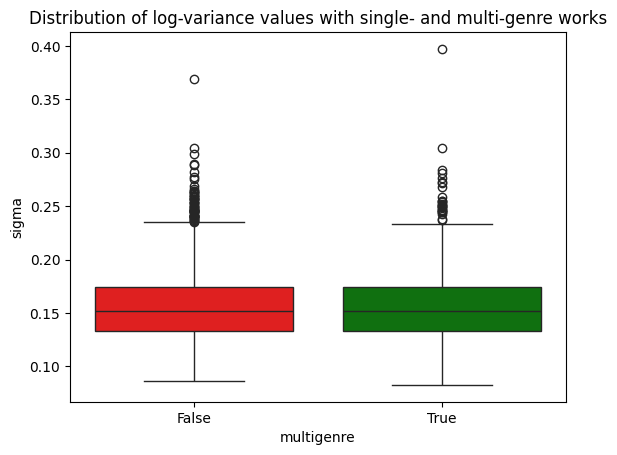

In [32]:
sns.boxplot(data=multigenre_sigma_info, x='multigenre', y='sigma', palette={'True': 'green', 'False': 'red'})
plt.title("Distribution of log-variance values with single- and multi-genre works");

In [33]:
linreg_genre = LinearRegression().fit(X=multigenre_sigma_info[['multigenre']], y=multigenre_sigma_info['sigma'])
linreg_genre.coef_.item()

0.0003773276554324216

In [34]:
p_val = permutation_test_score(linreg_genre, X=multigenre_sigma_info[['multigenre']], y=multigenre_sigma_info['sigma'], n_permutations=10000)

In [35]:
print(p_val[2].item())

0.8087191280871913
